<a href="https://colab.research.google.com/github/kalyanisingh19196-netizen/Neural-Networks-and-Deep-Learning-Lab/blob/main/Air_Quality_Forecasting.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!pip -q install xgboost shap

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from xgboost import XGBRegressor
import shap

print("All libraries imported successfully!")

All libraries imported successfully!


In [3]:
import requests

url = "https://github.com/Vonter/india-cpcb-aqi/raw/refs/heads/main/data/cpcb-aqi.csv.gz"

response = requests.get(url, timeout=120)
response.raise_for_status()

with open("/content/cpcb-aqi.csv.gz", "wb") as f:
    f.write(response.content)

print("Dataset downloaded successfully!")
print("File size:", round(len(response.content) / (1024 * 1024), 2), "MB")

Dataset downloaded successfully!
File size: 17.05 MB


In [4]:
import pandas as pd

file_path = "/content/cpcb-aqi.csv.gz"

df = pd.read_csv(file_path, compression="gzip")

print("Dataset loaded!")
print("Rows and columns:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())

display(df.head())

Dataset loaded!
Rows and columns: (562878, 29)

Column names:
['Station ID', 'State', 'City', 'Station Name', 'Date', '00:00:00', '01:00:00', '02:00:00', '03:00:00', '04:00:00', '05:00:00', '06:00:00', '07:00:00', '08:00:00', '09:00:00', '10:00:00', '11:00:00', '12:00:00', '13:00:00', '14:00:00', '15:00:00', '16:00:00', '17:00:00', '18:00:00', '19:00:00', '20:00:00', '21:00:00', '22:00:00', '23:00:00']


,Station ID,State,City,Station Name,Date,00:00:00,01:00:00,02:00:00,03:00:00,04:00:00,...,14:00:00,15:00:00,16:00:00,17:00:00,18:00:00,19:00:00,20:00:00,21:00:00,22:00:00,23:00:00
0,site_1406,Andhra Pradesh,Amaravati,Secretariat Amaravati APPCB,2017-12-11,NaN,NaN,NaN,NaN,NaN,...,178.0,196.0,205.0,201.0,114.0,136.0,126.0,253.0,232.0,200.0
1,site_1406,Andhra Pradesh,Amaravati,Secretariat Amaravati APPCB,2017-12-12,263.0,305.0,312.0,315.0,314.0,...,85.0,96.0,113.0,131.0,89.0,106.0,175.0,261.0,262.0,159.0
2,site_1406,Andhra Pradesh,Amaravati,Secretariat Amaravati APPCB,2017-12-13,137.0,176.0,216.0,208.0,159.0,...,135.0,138.0,146.0,140.0,115.0,160.0,138.0,108.0,112.0,89.0
3,site_1406,Andhra Pradesh,Amaravati,Secretariat Amaravati APPCB,2017-12-14,85.0,85.0,97.0,137.0,148.0,...,105.0,113.0,132.0,102.0,139.0,197.0,193.0,172.0,146.0,154.0
4,site_1406,Andhra Pradesh,Amaravati,Secretariat Amaravati APPCB,2017-12-15,127.0,135.0,134.0,151.0,166.0,...,125.0,136.0,143.0,134.0,108.0,146.0,188.0,243.0,194.0,188.0


In [5]:
print("Cities available:")
print(df["City"].dropna().unique()[:30])

print("\nMissing values in each column:")
print(df.isnull().sum().sort_values(ascending=False).head(10))

Cities available:
['Amaravati' 'Anantapur' 'Chittoor' 'Kadapa' 'Rajamahendravaram'
 'Tirupati' 'Vijayawada' 'Visakhapatnam' 'Naharlagun' 'Byrnihat'
 'Guwahati' 'Nagaon' 'Nalbari' 'Silchar' 'Sivasagar' 'Araria' 'Arrah'
 'Bettiah' 'Bhagalpur' 'Bihar Sharif' 'Darbhanga' 'Gaya' 'Hajipur'
 'Katihar' 'Kishanganj' 'Manguraha' 'Motihari' 'Munger' 'Muzaffarpur'
 'Patna']

Missing values in each column:
01:00:00    55211
06:00:00    53619
08:00:00    53172
04:00:00    51977
07:00:00    51961
05:00:00    50930
09:00:00    50259
03:00:00    49901
02:00:00    48656
10:00:00    45696
dtype: int64


In [6]:
from google.colab import files

files.download("/content/cpcb-aqi.csv.gz")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [7]:
print("Dataset shape:", df.shape)
print("\nAll columns:")
print(df.columns.tolist())

print("\nFirst 5 rows:")
display(df.head())

print("\nData types:")
print(df.dtypes)

Dataset shape: (562878, 29)

All columns:
['Station ID', 'State', 'City', 'Station Name', 'Date', '00:00:00', '01:00:00', '02:00:00', '03:00:00', '04:00:00', '05:00:00', '06:00:00', '07:00:00', '08:00:00', '09:00:00', '10:00:00', '11:00:00', '12:00:00', '13:00:00', '14:00:00', '15:00:00', '16:00:00', '17:00:00', '18:00:00', '19:00:00', '20:00:00', '21:00:00', '22:00:00', '23:00:00']

First 5 rows:


,Station ID,State,City,Station Name,Date,00:00:00,01:00:00,02:00:00,03:00:00,04:00:00,...,14:00:00,15:00:00,16:00:00,17:00:00,18:00:00,19:00:00,20:00:00,21:00:00,22:00:00,23:00:00
0,site_1406,Andhra Pradesh,Amaravati,Secretariat Amaravati APPCB,2017-12-11,NaN,NaN,NaN,NaN,NaN,...,178.0,196.0,205.0,201.0,114.0,136.0,126.0,253.0,232.0,200.0
1,site_1406,Andhra Pradesh,Amaravati,Secretariat Amaravati APPCB,2017-12-12,263.0,305.0,312.0,315.0,314.0,...,85.0,96.0,113.0,131.0,89.0,106.0,175.0,261.0,262.0,159.0
2,site_1406,Andhra Pradesh,Amaravati,Secretariat Amaravati APPCB,2017-12-13,137.0,176.0,216.0,208.0,159.0,...,135.0,138.0,146.0,140.0,115.0,160.0,138.0,108.0,112.0,89.0
3,site_1406,Andhra Pradesh,Amaravati,Secretariat Amaravati APPCB,2017-12-14,85.0,85.0,97.0,137.0,148.0,...,105.0,113.0,132.0,102.0,139.0,197.0,193.0,172.0,146.0,154.0
4,site_1406,Andhra Pradesh,Amaravati,Secretariat Amaravati APPCB,2017-12-15,127.0,135.0,134.0,151.0,166.0,...,125.0,136.0,143.0,134.0,108.0,146.0,188.0,243.0,194.0,188.0



Data types:
Station ID       object
State            object
City             object
Station Name     object
Date             object
00:00:00        float64
01:00:00        float64
02:00:00        float64
03:00:00        float64
04:00:00        float64
05:00:00        float64
06:00:00        float64
07:00:00        float64
08:00:00        float64
09:00:00        float64
10:00:00        float64
11:00:00        float64
12:00:00        float64
13:00:00        float64
14:00:00        float64
15:00:00        float64
16:00:00        float64
17:00:00        float64
18:00:00        float64
19:00:00        float64
20:00:00        float64
21:00:00        float64
22:00:00        float64
23:00:00        float64
dtype: object


In [8]:
# Remove accidental spaces from column names
df.columns = df.columns.astype(str).str.strip()

# Identify columns containing hourly times, e.g. 01:00:00
hour_cols = [
    col for col in df.columns
    if len(col) == 8 and col[2] == ":" and col[5] == ":"
]

print("Hourly columns found:", len(hour_cols))
print("Example hourly columns:", hour_cols[:5])

print("Other columns:")
print([col for col in df.columns if col not in hour_cols])

Hourly columns found: 24
Example hourly columns: ['00:00:00', '01:00:00', '02:00:00', '03:00:00', '04:00:00']
Other columns:
['Station ID', 'State', 'City', 'Station Name', 'Date']


In [9]:
# Check which columns identify the date and city
print(df.columns.tolist())

['Station ID', 'State', 'City', 'Station Name', 'Date', '00:00:00', '01:00:00', '02:00:00', '03:00:00', '04:00:00', '05:00:00', '06:00:00', '07:00:00', '08:00:00', '09:00:00', '10:00:00', '11:00:00', '12:00:00', '13:00:00', '14:00:00', '15:00:00', '16:00:00', '17:00:00', '18:00:00', '19:00:00', '20:00:00', '21:00:00', '22:00:00', '23:00:00']


In [10]:
# Convert the date column into proper dates
df["Date"] = pd.to_datetime(df["Date"], errors="coerce")

# Convert hourly AQI columns to numeric values
df[hour_cols] = df[hour_cols].apply(
    pd.to_numeric, errors="coerce"
)

# Calculate daily average AQI from available hourly readings
df["Daily_AQI"] = df[hour_cols].mean(axis=1)

# Keep rows with a valid date and AQI
daily = df.dropna(subset=["Date", "Daily_AQI"]).copy()

# Sort chronologically within each city and station
daily = daily.sort_values(["City", "Station ID", "Date"])

print("Daily dataset shape:", daily.shape)
display(daily[[
    "Date", "City", "Station ID", "Station Name", "Daily_AQI"
]].head(10))

Daily dataset shape: (562878, 30)


,Date,City,Station ID,Station Name,Daily_AQI
477503,2020-11-08,Agartala,site_5377,Kunjaban Agartala Tripura SPCB,88.600000
477504,2020-11-09,Agartala,site_5377,Kunjaban Agartala Tripura SPCB,70.739130
477505,2020-11-10,Agartala,site_5377,Kunjaban Agartala Tripura SPCB,70.000000
477506,2020-11-11,Agartala,site_5377,Kunjaban Agartala Tripura SPCB,88.086957
477507,2020-11-12,Agartala,site_5377,Kunjaban Agartala Tripura SPCB,77.125000
477508,2020-11-13,Agartala,site_5377,Kunjaban Agartala Tripura SPCB,61.608696
477509,2020-11-14,Agartala,site_5377,Kunjaban Agartala Tripura SPCB,142.260870
477510,2020-11-15,Agartala,site_5377,Kunjaban Agartala Tripura SPCB,235.217391
477511,2020-11-16,Agartala,site_5377,Kunjaban Agartala Tripura SPCB,192.217391
477512,2020-11-17,Agartala,site_5377,Kunjaban Agartala Tripura SPCB,154.869565


In [11]:
df["Hourly_Readings_Count"] = df[hour_cols].notna().sum(axis=1)

print(df["Hourly_Readings_Count"].describe())

print("\nRows with at least 18 hourly readings:")
print((df["Hourly_Readings_Count"] >= 18).sum())

print("\nRows with at least 1 hourly reading:")
print((df["Hourly_Readings_Count"] >= 1).sum())

count    562878.000000
mean         22.160292
std           4.203242
min           1.000000
25%          23.000000
50%          24.000000
75%          24.000000
max          24.000000
Name: Hourly_Readings_Count, dtype: float64

Rows with at least 18 hourly readings:
501972

Rows with at least 1 hourly reading:
562878


In [12]:
print(sorted(df["City"].dropna().unique()))

['Agartala', 'Agra', 'Ahmedabad', 'Ahmednagar', 'Aizawl', 'Ajmer', 'Akola', 'Alwar', 'Amaravati', 'Ambala', 'Amravati', 'Amritsar', 'Anantapur', 'Angul', 'Ankleshwar', 'Araria', 'Ariyalur', 'Arrah', 'Asansol', 'Aurangabad', 'Baddi', 'Badlapur', 'Bagalkot', 'Baghpat', 'Balasore', 'Ballabgarh', 'Banswara', 'Baran', 'Barbil', 'Bareilly', 'Baripada', 'Barmer', 'Barrackpore', 'Bathinda', 'Belapur', 'Bengaluru', 'Bettiah', 'Bhagalpur', 'Bhilai', 'Bhiwadi', 'Bhiwandi', 'Bhiwani', 'Bhopal', 'Bhubaneswar', 'Bidar', 'Bihar Sharif', 'Bikaner', 'Bilaspur', 'Bileipada', 'Boisar', 'Brajrajnagar', 'Bulandshahr', 'Bundi', 'Byasanagar', 'Byrnihat', 'Chamarajanagar', 'Chandigarh', 'Chandrapur', 'Charkhi Dadri', 'Chengalpattu', 'Chennai', 'Chhal', 'Chikkaballapur', 'Chikkamagaluru', 'Chittoor', 'Churu', 'Coimbatore', 'Cuddalore', 'Cuttack', 'Damoh', 'Darbhanga', 'Dausa', 'Davanagere', 'Dehradun', 'Delhi', 'Dhanbad', 'Dharuhera', 'Dharwad', 'Dholpur', 'Dhule', 'Dindigul', 'Dungarpur', 'Eloor', 'Ernakulam'

In [13]:
city_name = "Bengaluru"

city_data = daily[
    daily["City"].astype(str).str.lower() == city_name.lower()
].copy()

city_data = city_data.sort_values("Date")

print("Rows for selected city:", len(city_data))
display(city_data[["Date", "Station Name", "Daily_AQI"]].head(10))

Rows for selected city: 21413


,Date,Station Name,Daily_AQI
240962,2017-01-01,BTM Layout Bengaluru CPCB,64.000000
243274,2017-01-01,BWSSB Kadabesanahalli Bengaluru CPCB,50.416667
246972,2017-01-01,City Railway Station Bengaluru KSPCB,105.708333
240963,2017-01-02,BTM Layout Bengaluru CPCB,59.708333
243275,2017-01-02,BWSSB Kadabesanahalli Bengaluru CPCB,80.000000
246973,2017-01-02,City Railway Station Bengaluru KSPCB,114.857143
255427,2017-01-02,Peenya Bengaluru CPCB,77.666667
246974,2017-01-03,City Railway Station Bengaluru KSPCB,112.750000
255428,2017-01-03,Peenya Bengaluru CPCB,72.500000
240964,2017-01-03,BTM Layout Bengaluru CPCB,63.750000


In [14]:
# Keep only Bengaluru records with valid dates and AQI
city_data = city_data.dropna(
    subset=["Date", "Daily_AQI", "Station ID"]
).copy()

city_data["Date"] = pd.to_datetime(city_data["Date"]).dt.normalize()
city_data["Daily_AQI"] = pd.to_numeric(
    city_data["Daily_AQI"], errors="coerce"
)

city_data = city_data.dropna(subset=["Daily_AQI"])

# Keep one record per station per date
city_data = (
    city_data.groupby(
        ["Station ID", "Station Name", "City", "Date"],
        as_index=False
    )["Daily_AQI"].mean()
)

city_data = city_data.sort_values(["Station ID", "Date"])

print("Cleaned rows:", len(city_data))
print("Stations:", city_data["Station ID"].nunique())
display(city_data.head())

Cleaned rows: 21413
Stations: 1


,Station ID,Station Name,City,Date,Daily_AQI
0,site_5678,BTM Layout Bengaluru CPCB,Bengaluru,2017-01-01,64.000000
2312,site_5678,BWSSB Kadabesanahalli Bengaluru CPCB,Bengaluru,2017-01-01,50.416667
6010,site_5678,City Railway Station Bengaluru KSPCB,Bengaluru,2017-01-01,105.708333
1,site_5678,BTM Layout Bengaluru CPCB,Bengaluru,2017-01-02,59.708333
2313,site_5678,BWSSB Kadabesanahalli Bengaluru CPCB,Bengaluru,2017-01-02,80.000000


In [15]:
# Create next-day target and historical features per station
parts = []

for station_id, group in city_data.groupby("Station ID"):
    group = group.sort_values("Date").copy()

    # Only retain consecutive daily observations
    next_date = group["Date"].shift(-1)
    group["Target_Date"] = next_date

    group["Target_AQI"] = group["Daily_AQI"].shift(-1)

    for lag in range(1, 8):
        group[f"AQI_lag_{lag}"] = group["Daily_AQI"].shift(lag)

    # The target must be exactly one calendar day later
    group = group[
        (group["Target_Date"] - group["Date"]).dt.days == 1
    ]

    parts.append(group)

model_data = pd.concat(parts, ignore_index=True)

feature_cols = [f"AQI_lag_{i}" for i in range(1, 8)]

model_data = model_data.dropna(
    subset=feature_cols + ["Target_AQI"]
).sort_values("Date")

print("Rows ready for modelling:", len(model_data))
display(model_data[["Date", "Target_Date"] + feature_cols + ["Target_AQI"]].head())

Rows ready for modelling: 2531


,Date,Target_Date,AQI_lag_1,AQI_lag_2,AQI_lag_3,AQI_lag_4,AQI_lag_5,AQI_lag_6,AQI_lag_7,Target_AQI
2,2017-01-03,2017-01-04,63.750000,72.500000,112.750000,77.666667,114.857143,80.000000,59.708333,69.375000
3,2017-01-04,2017-01-05,110.391304,56.666667,69.375000,55.625000,63.750000,72.500000,112.750000,63.875000
4,2017-01-05,2017-01-06,115.434783,54.583333,63.875000,91.291667,110.391304,56.666667,69.375000,69.666667
5,2017-01-06,2017-01-07,58.500000,133.368421,69.666667,112.750000,115.434783,54.583333,63.875000,89.083333
6,2017-01-07,2017-01-08,140.187500,65.375000,89.083333,72.625000,58.500000,133.368421,69.666667,75.500000


In [16]:
from sklearn.ensemble import RandomForestRegressor
from xgboost import XGBRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

model_data = model_data.sort_values("Date").reset_index(drop=True)

split = int(len(model_data) * 0.8)
train = model_data.iloc[:split]
test = model_data.iloc[split:]

X_train = train[feature_cols]
X_test = test[feature_cols]
y_train = train["Target_AQI"]
y_test = test["Target_AQI"]

models = {
    "Random Forest": RandomForestRegressor(
        n_estimators=200, random_state=42, n_jobs=-1
    ),
    "XGBoost": XGBRegressor(
        n_estimators=300, max_depth=5, learning_rate=0.05,
        objective="reg:squarederror", random_state=42,
        n_jobs=-1
    )
}

results = []

# Persistence baseline: tomorrow = today's AQI
baseline_pred = X_test["AQI_lag_1"]

results.append({
    "Model": "Persistence baseline",
    "MAE": mean_absolute_error(y_test, baseline_pred),
    "RMSE": np.sqrt(mean_squared_error(y_test, baseline_pred)),
    "R2": r2_score(y_test, baseline_pred)
})

for name, model in models.items():
    model.fit(X_train, y_train)
    pred = model.predict(X_test)

    results.append({
        "Model": name,
        "MAE": mean_absolute_error(y_test, pred),
        "RMSE": np.sqrt(mean_squared_error(y_test, pred)),
        "R2": r2_score(y_test, pred)
    })

results_df = pd.DataFrame(results)
display(results_df)

,Model,MAE,RMSE,R2
0,Persistence baseline,33.593567,47.569781,-0.433443
1,Random Forest,27.241827,38.381376,0.066834
2,XGBoost,28.082886,39.473549,0.012970


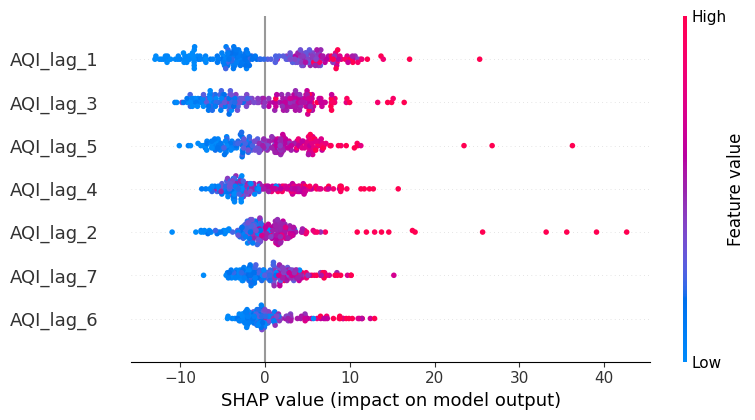

In [17]:
# Explain the Random Forest model
rf_model = models["Random Forest"]

explainer = shap.TreeExplainer(rf_model)
shap_values = explainer.shap_values(X_test.iloc[:200])

shap.summary_plot(shap_values, X_test.iloc[:200])

,Model,MAE,RMSE,R2
0,Random Forest,27.241827,38.381376,0.066834
1,XGBoost,28.082886,39.473549,0.012970
2,Persistence baseline,33.593567,47.569781,-0.433443


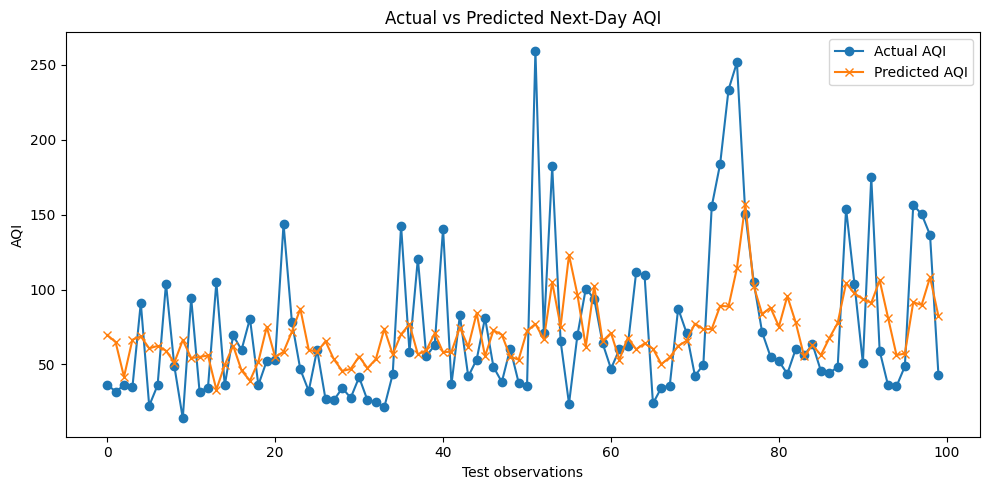

In [18]:
# Compare the performance of all models
display(
    results_df.sort_values("MAE").reset_index(drop=True)
)

# Plot actual vs predicted AQI for Random Forest
rf_model = models["Random Forest"]
rf_predictions = rf_model.predict(X_test)

plt.figure(figsize=(10, 5))
plt.plot(
    y_test.iloc[:100].to_numpy(),
    label="Actual AQI",
    marker="o"
)
plt.plot(
    rf_predictions[:100],
    label="Predicted AQI",
    marker="x"
)
plt.title("Actual vs Predicted Next-Day AQI")
plt.xlabel("Test observations")
plt.ylabel("AQI")
plt.legend()
plt.tight_layout()
plt.show()

In [19]:
def aqi_category(aqi):
    if aqi <= 50:
        return "Good"
    elif aqi <= 100:
        return "Satisfactory"
    elif aqi <= 200:
        return "Moderate"
    elif aqi <= 300:
        return "Poor"
    elif aqi <= 400:
        return "Very Poor"
    else:
        return "Severe"

def health_advisory(category):
    advice = {
        "Good": "Generally low pollution-related risk.",
        "Satisfactory": "Sensitive individuals should monitor symptoms.",
        "Moderate": "People with asthma or heart/lung conditions should take care.",
        "Poor": "Reduce prolonged or strenuous outdoor activity.",
        "Very Poor": "Avoid strenuous outdoor activity; sensitive groups should take extra care.",
        "Severe": "Minimise outdoor exposure and follow official local health guidance."
    }
    return advice[category]

# Example: interpret the first Random Forest prediction
predicted_aqi = max(0, float(rf_predictions[0]))
category = aqi_category(predicted_aqi)

print("Predicted next-day AQI:", round(predicted_aqi, 2))
print("AQI category:", category)
print("General advisory:", health_advisory(category))

Predicted next-day AQI: 69.68
AQI category: Satisfactory
General advisory: Sensitive individuals should monitor symptoms.


In [20]:
display(results_df.sort_values("MAE").reset_index(drop=True))

,Model,MAE,RMSE,R2
0,Random Forest,27.241827,38.381376,0.066834
1,XGBoost,28.082886,39.473549,0.012970
2,Persistence baseline,33.593567,47.569781,-0.433443


In [21]:
import joblib
import os

os.makedirs("/content/air_quality_project", exist_ok=True)

joblib.dump(
    models["Random Forest"],
    "/content/air_quality_project/air_quality_model.pkl"
)

print("Model saved successfully!")

Model saved successfully!


In [22]:
from google.colab import files

files.download(
    "/content/air_quality_project/air_quality_model.pkl"
)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [23]:
from google.colab import files

files.download("/content/air_quality_project/bengaluru_daily.csv")

FileNotFoundError: Cannot find file: /content/air_quality_project/bengaluru_daily.csv

In [24]:
import os

# Check whether city_data is still available
if "city_data" not in globals():
    print("city_data is missing. We need to rerun the data preparation cells.")
else:
    os.makedirs("/content/air_quality_project", exist_ok=True)

    city_data.to_csv(
        "/content/air_quality_project/bengaluru_daily.csv",
        index=False
    )

    print("CSV saved successfully!")
    print(os.listdir("/content/air_quality_project"))

CSV saved successfully!
['air_quality_model.pkl', 'bengaluru_daily.csv']


In [25]:
from google.colab import files

files.download("/content/air_quality_project/bengaluru_daily.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [26]:
# MULTI-CITY DATA PREPARATION

import pandas as pd
import numpy as np
import os

# Use the daily dataset created from all cities
all_city_data = daily.copy()

all_city_data["Date"] = pd.to_datetime(
    all_city_data["Date"], errors="coerce"
)

all_city_data["Daily_AQI"] = pd.to_numeric(
    all_city_data["Daily_AQI"], errors="coerce"
)

all_city_data = all_city_data.dropna(
    subset=["City", "Station ID", "Date", "Daily_AQI"]
)

all_city_data["Date"] = all_city_data["Date"].dt.normalize()

# Remove duplicate station/date records
all_city_data = all_city_data.groupby(
    ["City", "Station ID", "Station Name", "Date"],
    as_index=False
)["Daily_AQI"].mean()

all_city_data = all_city_data.sort_values(
    ["City", "Station ID", "Date"]
)

# Create next-day target and seven historical AQI features
parts = []

for (city, station), group in all_city_data.groupby(
    ["City", "Station ID"]
):
    group = group.sort_values("Date").copy()

    group["Target_Date"] = group["Date"].shift(-1)
    group["Target_AQI"] = group["Daily_AQI"].shift(-1)

    for lag in range(1, 8):
        group[f"AQI_lag_{lag}"] = group["Daily_AQI"].shift(lag)

    group = group[
        (group["Target_Date"] - group["Date"]).dt.days == 1
    ]

    parts.append(group)

model_data = pd.concat(parts, ignore_index=True)

FEATURES = [f"AQI_lag_{i}" for i in range(1, 8)]

model_data = model_data.dropna(
    subset=FEATURES + ["Target_AQI"]
)

print("Cities available:")
print(sorted(all_city_data["City"].unique()))

print("\nTotal cities:", all_city_data["City"].nunique())
print("Total stations:", all_city_data["Station ID"].nunique())
print("Training samples:", len(model_data))

Cities available:
['Agartala', 'Agra', 'Ahmedabad', 'Ahmednagar', 'Aizawl', 'Ajmer', 'Akola', 'Alwar', 'Amaravati', 'Ambala', 'Amravati', 'Amritsar', 'Anantapur', 'Angul', 'Ankleshwar', 'Araria', 'Ariyalur', 'Arrah', 'Asansol', 'Aurangabad', 'Baddi', 'Badlapur', 'Bagalkot', 'Baghpat', 'Balasore', 'Ballabgarh', 'Banswara', 'Baran', 'Barbil', 'Bareilly', 'Baripada', 'Barmer', 'Barrackpore', 'Bathinda', 'Belapur', 'Bengaluru', 'Bettiah', 'Bhagalpur', 'Bhilai', 'Bhiwadi', 'Bhiwandi', 'Bhiwani', 'Bhopal', 'Bhubaneswar', 'Bidar', 'Bihar Sharif', 'Bikaner', 'Bilaspur', 'Bileipada', 'Boisar', 'Brajrajnagar', 'Bulandshahr', 'Bundi', 'Byasanagar', 'Byrnihat', 'Chamarajanagar', 'Chandigarh', 'Chandrapur', 'Charkhi Dadri', 'Chengalpattu', 'Chennai', 'Chhal', 'Chikkaballapur', 'Chikkamagaluru', 'Chittoor', 'Churu', 'Coimbatore', 'Cuddalore', 'Cuttack', 'Damoh', 'Darbhanga', 'Dausa', 'Davanagere', 'Dehradun', 'Delhi', 'Dhanbad', 'Dharuhera', 'Dharwad', 'Dholpur', 'Dhule', 'Dindigul', 'Dungarpur', 'E

In [27]:
# MULTI-CITY MODEL TRAINING

from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np
import pandas as pd
import joblib
import os

FEATURES = [f"AQI_lag_{i}" for i in range(1, 8)]

# Sort chronologically and split by target date
model_data = model_data.sort_values("Target_Date").reset_index(drop=True)

cutoff = model_data["Target_Date"].quantile(0.80)

train = model_data[model_data["Target_Date"] < cutoff].copy()
test = model_data[model_data["Target_Date"] >= cutoff].copy()

X_train = train[FEATURES]
y_train = train["Target_AQI"]

X_test = test[FEATURES]
y_test = test["Target_AQI"]

# Train Random Forest
multi_city_model = RandomForestRegressor(
    n_estimators=200,
    max_depth=15,
    min_samples_leaf=2,
    random_state=42,
    n_jobs=-1
)

multi_city_model.fit(X_train, y_train)

# Evaluate
predictions = multi_city_model.predict(X_test)

print("MULTI-CITY MODEL RESULTS")
print("------------------------")
print("MAE:", round(mean_absolute_error(y_test, predictions), 2))
print("RMSE:", round(np.sqrt(mean_squared_error(y_test, predictions)), 2))
print("R2:", round(r2_score(y_test, predictions), 3))

# Compare with persistence baseline
baseline = X_test["AQI_lag_1"]

print("\nPERSISTENCE BASELINE")
print("MAE:", round(mean_absolute_error(y_test, baseline), 2))
print("RMSE:", round(np.sqrt(mean_squared_error(y_test, baseline)), 2))

# Save model and complete multi-city data
output_folder = "/content/air_quality_project"
os.makedirs(output_folder, exist_ok=True)

joblib.dump(
    multi_city_model,
    output_folder + "/air_quality_model.pkl",
    compress=3
)

all_city_data.to_csv(
    output_folder + "/all_india_daily.csv",
    index=False
)

print("\nModel and multi-city dataset saved successfully!")
print("Model size (MB):", round(
    os.path.getsize(output_folder + "/air_quality_model.pkl") / (1024*1024), 2
))

MULTI-CITY MODEL RESULTS
------------------------
MAE: 26.5
RMSE: 39.49
R2: 0.687

PERSISTENCE BASELINE
MAE: 28.32
RMSE: 44.39

Model and multi-city dataset saved successfully!
Model size (MB): 69.8


In [28]:
# CREATE A SMALLER MULTI-CITY MODEL

from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np
import os
import joblib

small_model = RandomForestRegressor(
    n_estimators=40,
    max_depth=10,
    min_samples_leaf=3,
    random_state=42,
    n_jobs=-1
)

small_model.fit(X_train, y_train)

small_predictions = small_model.predict(X_test)

print("SMALL MODEL RESULTS")
print("MAE:", round(mean_absolute_error(y_test, small_predictions), 2))
print("RMSE:", round(np.sqrt(mean_squared_error(y_test, small_predictions)), 2))
print("R2:", round(r2_score(y_test, small_predictions), 3))

# Save compressed model
model_path = "/content/air_quality_project/air_quality_model.pkl"

joblib.dump(small_model, model_path, compress=3)

size_mb = os.path.getsize(model_path) / (1024 * 1024)

print("New model size:", round(size_mb, 2), "MB")

SMALL MODEL RESULTS
MAE: 26.45
RMSE: 39.41
R2: 0.688
New model size: 1.78 MB


In [29]:
from google.colab import files

files.download(
    "/content/air_quality_project/air_quality_model.pkl"
)

files.download(
    "/content/air_quality_project/all_india_daily.csv"
)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [30]:
from google.colab import files

files.download(
    "/content/air_quality_project/air_quality_model.pkl"
)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [31]:
import joblib
import os

# Load your trained multi-city model
model_path = "/content/air_quality_project/air_quality_model.pkl"

model = joblib.load(model_path)

# Compress and save the model
joblib.dump(
    model,
    model_path,
    compress=3
)

# Check compressed size
size_mb = os.path.getsize(model_path) / (1024 * 1024)

print("Model compressed successfully!")
print("New model size:", round(size_mb, 2), "MB")

Model compressed successfully!
New model size: 1.95 MB


In [32]:
from google.colab import files

files.download(
    "/content/air_quality_project/air_quality_model.pkl"
)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>